In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class bsplines1D:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
    

        # 1D trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-2)

        # Define the non-trainable coeff based on the Dirichlet boundary conditions.
        self.coeffs = torch.tensor([0.0,0.0])
        self.coeffs_trainable.requires_grad_()
        
        

        
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x, self.knot_x ) for i in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        

        # Adding the internal domain bsplines
        for i in range(1,(self.n_basis-1)):
            y += self.coeffs_trainable[i-1] *self.B_x[i]

        #Adding the BC domain bsplines based on the BC coefficeints
        y += self.coeffs[0]*self.B_x[0]+self.coeffs[1]*self.B_x[self.n_basis-1]

        return y

In [3]:
torch.manual_seed(42)
# model_bc = bsplines1D(10,3)
model_bc = bsplines1D(20,3)

In [4]:
x = torch.linspace(0,1,1000)
y = model_bc.forward(x)


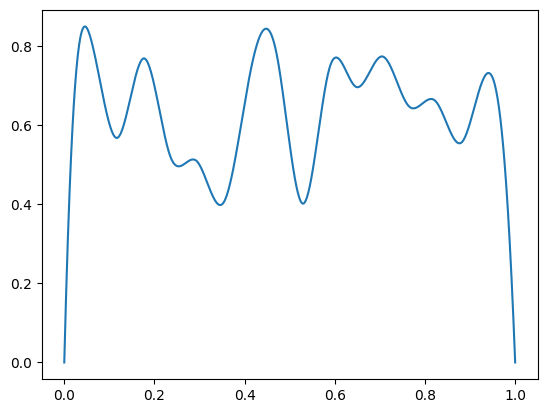

In [5]:
plt.plot(x,y.detach().numpy())

In [6]:
u_exact = torch.sin(torch.pi*x)

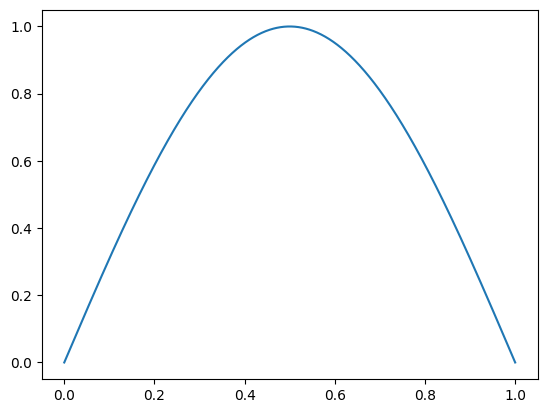

In [7]:
plt.plot(x,u_exact)

In [8]:
# Learning rate
learning_rate = 0.001

# Number of iterations
epochs = 1000000

###########Changes#################
optimizer = torch.optim.Adam([model_bc.coeffs_trainable], lr=learning_rate)
###################################

# Training loop (manual gradient descent)
for epoch in range(epochs):
    # Forward pass: y = slope * x + intercept
    # y_pred = torch.einsum('bij,bi->j',phi, nodal_values)

    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    y_pred = model_bc.forward(x)
    
    # Compute model first derivative wrt x

    loss = torch.mean((y_pred-u_exact) ** 2)

    # Compute Mean Squared Error (MSE) loss
    # loss = torch.mean((y_pred - y) ** 2)
    
    # Backward pass: compute gradients
    loss.backward()
    ###########Changes#################
    optimizer.step()
    
    # # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model_bc.coeffs_trainable -= learning_rate * model_bc.coeffs_trainable.grad
    
    # # Zero the gradients after each update
    # model_bc.coeffs_trainable.grad.zero_()
    # # x.grad.zero_()
    ###########Changes#################
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/1000000], Loss: 0.10622808337211609
Epoch [10/1000000], Loss: 0.10369706898927689
Epoch [15/1000000], Loss: 0.1012132465839386
Epoch [20/1000000], Loss: 0.09877888858318329
Epoch [25/1000000], Loss: 0.096395343542099
Epoch [30/1000000], Loss: 0.09406360983848572
Epoch [35/1000000], Loss: 0.09178443998098373
Epoch [40/1000000], Loss: 0.08955828845500946
Epoch [45/1000000], Loss: 0.08738518506288528
Epoch [50/1000000], Loss: 0.08526472747325897
Epoch [55/1000000], Loss: 0.08319626748561859
Epoch [60/1000000], Loss: 0.08117902278900146
Epoch [65/1000000], Loss: 0.07921212166547775
Epoch [70/1000000], Loss: 0.07729461044073105
Epoch [75/1000000], Loss: 0.07542545348405838
Epoch [80/1000000], Loss: 0.07360362261533737
Epoch [85/1000000], Loss: 0.07182805985212326
Epoch [90/1000000], Loss: 0.07009771466255188
Epoch [95/1000000], Loss: 0.06841151416301727
Epoch [100/1000000], Loss: 0.06676840782165527
Epoch [105/1000000], Loss: 0.0651673823595047
Epoch [110/1000000], Loss: 0.06360740

KeyboardInterrupt: 

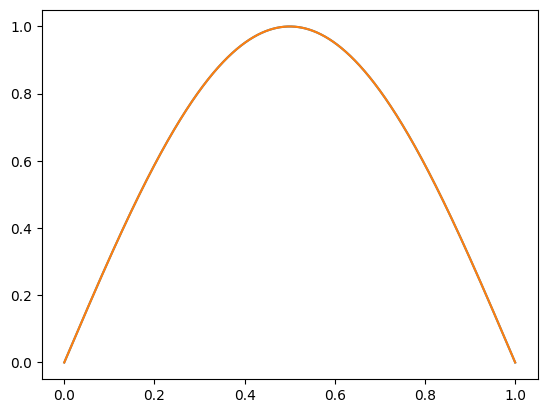

In [9]:

plt.plot(x,u_exact)
plt.plot(x,y_pred.detach().numpy())

In [10]:
# These are the coefficients after training and fitting the BC.
IC_coefficients = model_bc.coeffs_trainable

In [11]:
IC_coefficients.requires_grad_(False)

tensor([0.0616, 0.1848, 0.3633, 0.5294, 0.6775, 0.8026, 0.9003, 0.9673, 1.0014,
        1.0014, 0.9673, 0.9003, 0.8026, 0.6775, 0.5294, 0.3633, 0.1848, 0.0616])

In [12]:
IC_coefficients = torch.nn.functional.pad(IC_coefficients, (1, 1), mode='constant', value=0.0)

In [13]:
torch.save(IC_coefficients, './results/wave_equation/ic_coeff_20_3.pt')

Applying the BCs $u(0,t)=u(1,t)=0$ and the one IC $u(x,0)=sin(\pi x)$

In [3]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [4]:
IC_coefficients = torch.load('./results/wave_equation/ic_coeff_20_3.pt')

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_9660\2861350844.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  IC_coefficients = torch.load('./results/wave_equation/ic_

In [5]:
class bsplines2D:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-1, n_basis-2)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        self.coeffs_row_0=IC_coefficients
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])
        
        
        y = torch.zeros(x.shape[0])
        # Adding the internal domain bsplines
        for i in range(1,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-1, j-1] * self.B_t[i]*self.B_x[j]
        
        # Adding the IC 
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y

In [4]:
# model = bsplines2D(10,3)
torch.manual_seed(42)
model = bsplines2D(20,3)

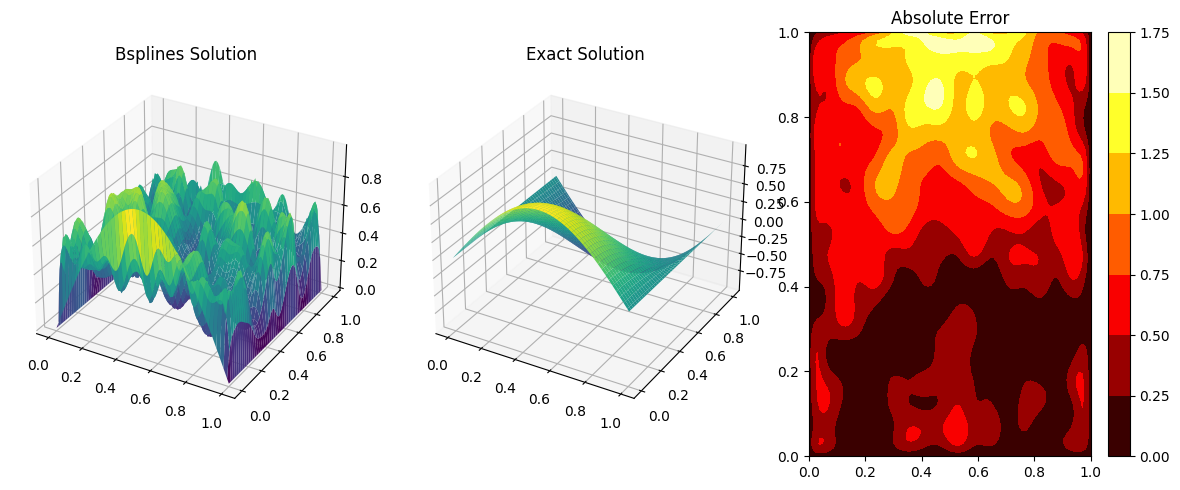

In [5]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Tg)

# 📈 Plot predicted vs exact
fig = plt.figure(figsize=(12, 5))

# PINN solution
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(Xg, Tg, u_pred, cmap='viridis')
ax1.set_title("Bsplines Solution")

# Exact solution
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(Xg, Tg, u_exact, cmap='viridis')
ax2.set_title("Exact Solution")

# Absolute error
ax3 = fig.add_subplot(133)
error = np.abs(u_pred - u_exact)
c = ax3.contourf(Xg, Tg, error, cmap='hot')
fig.colorbar(c, ax=ax3)
ax3.set_title("Absolute Error")

plt.tight_layout()
plt.show()

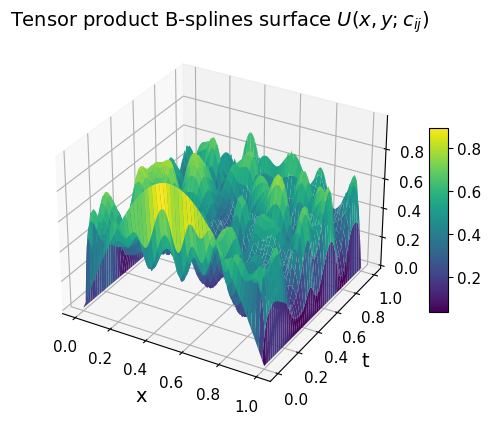

In [6]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)
# fig, axs = plt.subplots(1, 3, figsize=(15, 4))


# Plot surface
surf = ax.plot_surface(Xg, Yg, u_pred, cmap='viridis')  # Note the .T for correct orientation

# Add labels and colorbar
ax.set_title('Tensor product B-splines surface $U(x,y;c_{ij})$',fontsize=14)
ax.set_xlabel('x',fontsize=14)
ax.set_ylabel('t',fontsize=14)
ax.set_zlabel('u',fontsize=14)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10).ax.tick_params(labelsize=11) 
ax.tick_params(axis='both', labelsize=11)
plt.savefig("surface_DCIC_wave.pdf")
plt.show()

Next step to impose the Neumann IC, namely the velocity of the Initial displacement field of the string IC: $\theta u/ \theta t(x,0)=0$

We train for residual $res=\theta u/ \theta t(x,0)$ and we realize that only the first row of the trainable coefficients parameters is changing, because the 1st and 2nd bsplines derivatives of the   have compact support but the 1st row has already been fixed for the IC, so in the domain (x,0) only the coefficients of the first row are affected by the Neuman condition. 

In [6]:
torch.manual_seed(42)
X = torch.rand(1000, 2)
X[:,1] = 0.0
X.requires_grad_(True)

tensor([[0.8823, 0.0000],
        [0.3829, 0.0000],
        [0.3904, 0.0000],
        ...,
        [0.0256, 0.0000],
        [0.2608, 0.0000],
        [0.1775, 0.0000]], requires_grad=True)

In [7]:
epochs = 100000
learning_rate=1e-3



for epoch in range(epochs):
    
    
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = grads[:, 1]

    # Residual loss
    res = u_t  
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    with torch.no_grad():
        model.coeffs_trainable -= learning_rate * model.coeffs_trainable.grad
    # Zero the gradients after each update
    model.coeffs_trainable.grad.zero_()
    # x.grad.zero_()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 52.731868743896484
Epoch [10/100000], Loss: 16.51861572265625
Epoch [15/100000], Loss: 8.414752960205078
Epoch [20/100000], Loss: 5.126351833343506
Epoch [25/100000], Loss: 3.4247710704803467
Epoch [30/100000], Loss: 2.4237637519836426
Epoch [35/100000], Loss: 1.7822253704071045
Epoch [40/100000], Loss: 1.3451828956604004
Epoch [45/100000], Loss: 1.0341898202896118
Epoch [50/100000], Loss: 0.8059381246566772
Epoch [55/100000], Loss: 0.6346601247787476
Epoch [60/100000], Loss: 0.5040273666381836
Epoch [65/100000], Loss: 0.4031502902507782
Epoch [70/100000], Loss: 0.3244752883911133
Epoch [75/100000], Loss: 0.2626076936721802
Epoch [80/100000], Loss: 0.2136080265045166
Epoch [85/100000], Loss: 0.17455194890499115
Epoch [90/100000], Loss: 0.14324134588241577
Epoch [95/100000], Loss: 0.11800610274076462
Epoch [100/100000], Loss: 0.09756673872470856
Epoch [105/100000], Loss: 0.08093524724245071
Epoch [110/100000], Loss: 0.06734417378902435
Epoch [115/100000], Loss: 0

KeyboardInterrupt: 

In [8]:
IC_neuman_coeffs = model.coeffs_trainable[0,:]
IC_neuman_coeffs = IC_neuman_coeffs.detach()
IC_neuman_coeffs = torch.nn.functional.pad(IC_neuman_coeffs, (1, 1), mode='constant', value=0.0)

In [9]:
IC_neuman_coeffs

tensor([0.0000, 0.0616, 0.1848, 0.3633, 0.5294, 0.6775, 0.8026, 0.9003, 0.9673,
        1.0014, 1.0014, 0.9673, 0.9003, 0.8026, 0.6775, 0.5294, 0.3633, 0.1848,
        0.0616, 0.0000])

In [10]:
torch.save(IC_neuman_coeffs, './results/wave_equation/ic_neum_coeff_20_3.pt')

Finally after applying the BC and ICs in the PI bsplines network we are training the PDE

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
IC_coefficients = torch.load('./results/wave_equation/ic_coeff_20_3.pt')
IC_neuman_coeffs = torch.load('./results/wave_equation/ic_neum_coeff_20_3.pt')

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_37032\2491872304.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  IC_coefficients = torch.load('./results/wave_equation/ic

In [3]:
# torch.manual_seed(42)
class bsplines2D:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-2, n_basis-2)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        self.coeffs_row_0=IC_coefficients
        self.coeffs_row_1=IC_neuman_coeffs
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])
        
        
        y = torch.zeros(x.shape[0])
        # Adding the internal domain bsplines
        for i in range(2,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-2, j-1] * self.B_t[i]*self.B_x[j]
        
        # Adding the Dirichlet IC  
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]
        
        # Adding the Neumann IC in the second row  
        for i in range(self.n_basis):
            y += self.coeffs_row_1[i]*self.B_t[1]*self.B_x[i]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y

In [4]:
torch.manual_seed(42)

# model = bsplines2D(10,3)
model = bsplines2D(20,3)

In [5]:
model.coeffs_trainable.shape

torch.Size([18, 18])

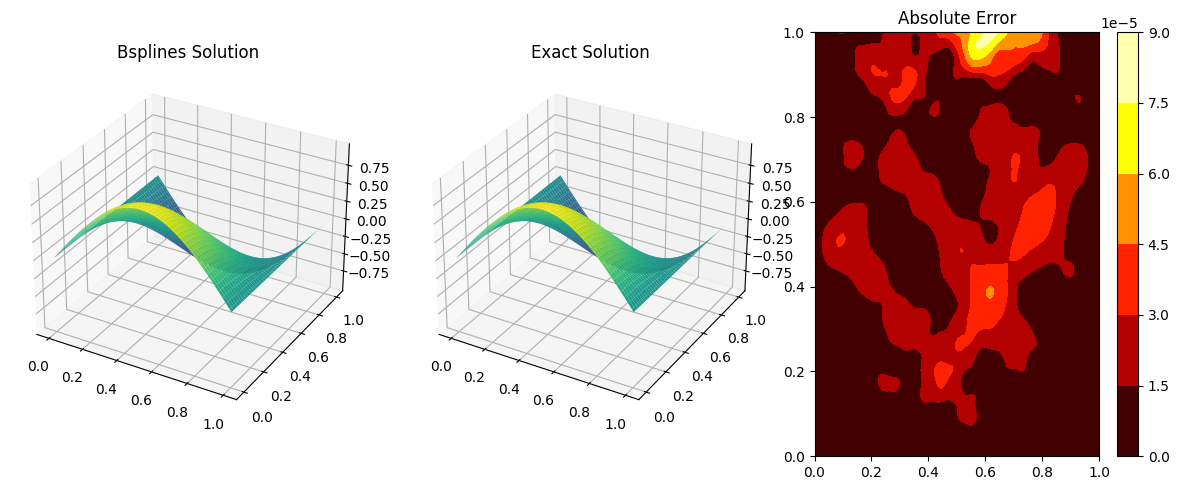

: 

In [28]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Tg)

# 📈 Plot predicted vs exact
fig = plt.figure(figsize=(12, 5))

# PINN solution
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(Xg, Tg, u_pred, cmap='viridis')
ax1.set_title("Bsplines Solution")

# Exact solution
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(Xg, Tg, u_exact, cmap='viridis')
ax2.set_title("Exact Solution")

# Absolute error
ax3 = fig.add_subplot(133)
error = np.abs(u_pred - u_exact)
c = ax3.contourf(Xg, Tg, error, cmap='hot')
fig.colorbar(c, ax=ax3)
ax3.set_title("Absolute Error")

plt.tight_layout()
plt.show()

In [6]:
# Check that the Neuman is correct.
torch.manual_seed(42)
X = torch.rand(1000, 2)
X[:,1] = 0.0
X.requires_grad_(True)
u = model.forward(X)
grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
u_t = grads[:, 1]
# The interval of the values should be close to zero u_t=0
print(u_t.min(), u_t.max())

tensor(-4.5776e-05, grad_fn=<MinBackward1>) tensor(4.1962e-05, grad_fn=<MaxBackward1>)


In [6]:
torch.manual_seed(42)
colloc_points = 5000

#X[:,0] is x and X[:,1] is time
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)
# X[:, 1] = 0.1
X.requires_grad_(True)

tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], requires_grad=True)

In [9]:
# After 45000 I run this for 1e-4 and got -5 loss and accuracy
epochs = 45000
# learning_rate=1e-3
learning_rate=1e-4

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable], lr=learning_rate)
###########Changes#################

# loss_vec= []

for epoch in range(epochs):
    
    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, X, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    # Residual loss
    res = u_tt -u_xx 
    
    loss = torch.mean(res**2)
    
    loss.backward()
     ###########Changes#################
    optimizer.step()
    
    # # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs_trainable -= learning_rate * model.coeffs_trainable.grad
    # # Zero the gradients after each update
    # model.coeffs_trainable.grad.zero_()
    # # x.grad.zero_()
    ###########Changes#################
    
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/45000], Loss: 0.0031044469214975834
Epoch [10/45000], Loss: 0.0015952438116073608
Epoch [15/45000], Loss: 0.0008895397186279297
Epoch [20/45000], Loss: 0.0005135284154675901
Epoch [25/45000], Loss: 0.00031179090728983283
Epoch [30/45000], Loss: 0.00020225532352924347
Epoch [35/45000], Loss: 0.00014257403381634504
Epoch [40/45000], Loss: 0.00010981004015775397
Epoch [45/45000], Loss: 9.300139936385676e-05
Epoch [50/45000], Loss: 8.615940896561369e-05
Epoch [55/45000], Loss: 8.363762026419863e-05
Epoch [60/45000], Loss: 8.089498442132026e-05
Epoch [65/45000], Loss: 7.770516822347417e-05
Epoch [70/45000], Loss: 7.590681343572214e-05
Epoch [75/45000], Loss: 7.541690138168633e-05
Epoch [80/45000], Loss: 7.468825060641393e-05
Epoch [85/45000], Loss: 7.42047413950786e-05
Epoch [90/45000], Loss: 7.426555384881794e-05
Epoch [95/45000], Loss: 7.410082616843283e-05
Epoch [100/45000], Loss: 7.398593152174726e-05
Epoch [105/45000], Loss: 7.400650792988017e-05
Epoch [110/45000], Loss: 7.396

KeyboardInterrupt: 

In [1]:
#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable }
torch.save(params, './results/wave_equation/model_bsplines1.pth')

NameError: name 'model' is not defined

In [7]:
# Load model trainable parameters
model_s = bsplines2D(20,3)
loaded_params = torch.load('./results/wave_equation/model_bsplines.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_37032\3915214379.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/wave_equation/mode

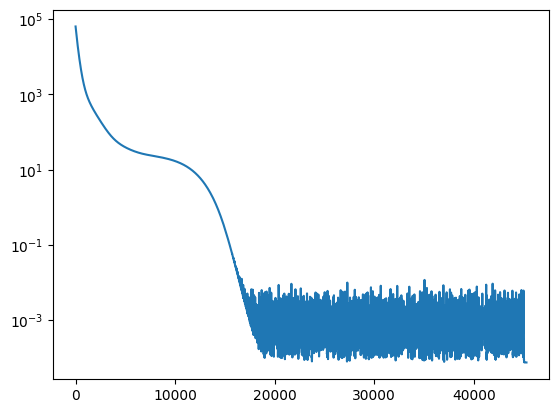

In [10]:
plt.plot(loss_vec)
plt.yscale('log')

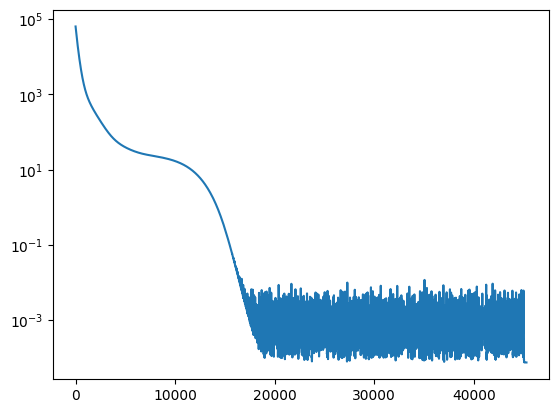

In [27]:
plt.plot(loss_bsplines_s)
plt.yscale('log')

In [24]:
# Save the loss function
loss_vec_npy = np.array(loss_vec)
np.save('./results/wave_equation/bsplines_loss.npy',loss_vec_npy)

In [8]:
# Load the loss function
loss_bsplines_s = np.load('./results/wave_equation/bsplines_loss.npy')


In [26]:
print(loss_bsplines_s)

[6.45078867e+04 6.41325195e+04 6.37588594e+04 ... 7.39179814e-05
 7.39086390e-05 7.39086172e-05]


PINN solution

In [55]:

# First we are implementing hyperparameter tuning based on optuna with Tree-structured Parzen Estimator (TPE) algorithm.
import torch.autograd as autograd
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import optuna
import random
torch.manual_seed(42)
# Device

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # Force deterministic behavior in CuDNN (can slow training)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.layers = nn.ModuleList()
        self.activation = nn.Tanh()
        for i in range(len(layers)-1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))

    def forward(self, x):
        for i in range(len(self.layers)-1):
            x = self.activation(self.layers[i](x))
        x = self.layers[-1](x)
        return x

def pde_residual(model, x_t):
    x_t.requires_grad_(True)
    u = model(x_t)

    grads = torch.autograd.grad(u, x_t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, x_t, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, x_t, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    return u_tt -u_xx 

def generate_training_points(n_interior, n_boundary, n_initial):
    # Interior points u(x,t)
    x_in = torch.rand(n_interior, 1)
    t_in = torch.rand(n_interior, 1)
    interior = torch.cat([x_in, t_in], dim=1)

    # Boundary points u(0,t)=u(1,t)
    t_b = torch.rand(n_boundary, 1)
    zeros = torch.zeros(n_boundary // 2, 1)
    ones = torch.ones(n_boundary // 2, 1)
    # half points right x=0,  half points left boundary x=1
    b1 = torch.cat([zeros, t_b[:n_boundary // 2]], dim=1)
    b2 = torch.cat([ones, t_b[n_boundary // 2:]], dim=1)
    boundary = torch.cat([b1, b2], dim=0)

    # Initial points u(x,0)
    x_i = torch.rand(n_initial, 1)
    t_i = torch.zeros(n_initial, 1)
    initial = torch.cat([x_i, t_i], dim=1)

    return interior, boundary, initial


# # Train the model
# layers = [2, 20, 20, 20, 1]
# model = PINN(layers).to(device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# X_in, X_b = generate_training_points(5000, 50)


# Hyperparameter tuning 

def objective(trial):
    # Sample hyperparameters
    n_layers = trial.suggest_int("n_layers", 2, 5)
    n_neurons = trial.suggest_int("n_neurons", 10, 100)
    learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)

    # Build layers list
    layers = [2] + [n_neurons] * n_layers + [1]
    model = PINN(layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


    # Generate training data
    n_interior, n_boundary, n_initial = 5000, 1000, 1000
    interior, boundary, initial = generate_training_points(n_interior, n_boundary, n_initial)
    interior, boundary, initial = interior.to(device), boundary.to(device), initial.to(device)

    # Train for a small number of epochs
    for epoch in range(2000):
        optimizer.zero_grad()

        f_interior = pde_residual(model, interior)
        loss_pde = torch.mean(f_interior**2)

        u_boundary = model(boundary)
        loss_bc = torch.mean(u_boundary**2)

        u_initial_pred = model(initial)
        u_initial_true = torch.sin(np.pi * initial[:, 0:1])
        loss_ic = torch.mean((u_initial_pred - u_initial_true) ** 2)
        
        loss = loss_pde + loss_bc + loss_ic
        
        loss.backward()
        optimizer.step()

    return loss.item()

# ---- Run Optuna study ---- #
if __name__ == "__main__":
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=20)

    print("Best trial:")
    trial = study.best_trial
    print(f"  Loss: {trial.value}")
    print("  Best hyperparameters:")
    for key, value in trial.params.items():
        print(f"    {key}: {value}")

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-07-23 10:51:09,226] A new study created in memory with name: no-name-8ef205ec-5e1a-4f72-ae26-b3811235b6b4
C:\Users\Polydoras\AppData\Local\Temp\ipykernel_91852\401587466.py:92: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)
[I 2025-07-23 10:51:18,636] Trial 0 finished with value: 0.00010404545173514634 and parameters: {'n_layers': 3, 'n_neurons': 96, 'lr': 0.0029106359131330704}. Best is trial 0 with value: 0.00010404545173514634.
[I 2025-07-23 10:51:29,428] Trial 1 finished with value: 0.

Best trial:
  Loss: 0.00010404545173514634
  Best hyperparameters:
    n_layers: 3
    n_neurons: 96
    lr: 0.0029106359131330704


In [9]:
# Now train with the tuned hyperparameters

import torch
import torch.nn as nn
import torch.autograd as autograd
import numpy as np
import matplotlib.pyplot as plt


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.layers = nn.ModuleList()
        self.activation = nn.Tanh()
        for i in range(len(layers)-1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))

    def forward(self, x):
        for i in range(len(self.layers)-1):
            x = self.activation(self.layers[i](x))
        x = self.layers[-1](x)
        return x

In [20]:


def pde_residual(model, x_t):
    x_t.requires_grad_(True)
    u = model(x_t)

    grads = torch.autograd.grad(u, x_t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, x_t, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, x_t, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    return u_tt -u_xx 

def generate_training_points(n_interior, n_boundary, n_initial):
    # Interior points u(x,t)
    x_in = torch.rand(n_interior, 1)
    t_in = torch.rand(n_interior, 1)
    interior = torch.cat([x_in, t_in], dim=1)

    # Boundary points u(0,t)=u(1,t)
    t_b = torch.rand(n_boundary, 1)
    zeros = torch.zeros(n_boundary // 2, 1)
    ones = torch.ones(n_boundary // 2, 1)
    # half points right x=0,  half points left boundary x=1
    b1 = torch.cat([zeros, t_b[:n_boundary // 2]], dim=1)
    b2 = torch.cat([ones, t_b[n_boundary // 2:]], dim=1)
    boundary = torch.cat([b1, b2], dim=0)

    # Initial points u(x,0)
    x_i = torch.rand(n_initial, 1)
    t_i = torch.zeros(n_initial, 1)
    initial = torch.cat([x_i, t_i], dim=1)

    return interior, boundary, initial

# model = PINN([2, 20, 20, 20, 1]).to(device)
# model = PINN([2, 92, 92, 92, 1]).to(device)
model = PINN([2, 96, 96, 96, 1]).to(device)
# model = PINN([2, 73, 73, 73, 1]).to(device)






In [28]:
# learning_rate = 2e-3
# learning_rate = 1e-3
model.to(device)
learning_rate = 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
n_iter = 15000
n_interior, n_boundary, n_initial = 5000, 1000, 1000
# loss_vec = []
for it in range(n_iter):
    interior, boundary, initial = generate_training_points(n_interior, n_boundary, n_initial)
    interior, boundary, initial = interior.to(device), boundary.to(device), initial.to(device)

    optimizer.zero_grad()

    f_interior = pde_residual(model, interior)
    loss_pde = torch.mean(f_interior**2)

    u_boundary = model(boundary)
    loss_bc = torch.mean(u_boundary**2)

    u_initial_pred = model(initial)
    u_initial_true = torch.sin(np.pi * initial[:, 0:1])
    loss_ic = torch.mean((u_initial_pred - u_initial_true) ** 2)

    loss = loss_pde + loss_bc + loss_ic
    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())

    if it % 500 == 0:
        print(f"Iteration {it}: Loss = {loss.item()}")

print("Training finished.")



Iteration 0: Loss = 1.6253098920060438e-06
Iteration 500: Loss = 1.8268074200022966e-06
Iteration 1000: Loss = 1.7196580301970243e-06
Iteration 1500: Loss = 1.6389470829381025e-06
Iteration 2000: Loss = 1.6033512793001137e-06
Iteration 2500: Loss = 1.6191403346965672e-06
Iteration 3000: Loss = 1.6154638160514878e-06
Iteration 3500: Loss = 1.7328349031231483e-06
Iteration 4000: Loss = 1.6484889329149155e-06
Iteration 4500: Loss = 1.6053314766395488e-06
Iteration 5000: Loss = 1.6476726614200743e-06
Iteration 5500: Loss = 1.6756841887399787e-06
Iteration 6000: Loss = 1.627885467314627e-06
Iteration 6500: Loss = 1.6603021322225686e-06
Iteration 7000: Loss = 1.5264409967130632e-06
Iteration 7500: Loss = 1.5162084991970914e-06
Iteration 8000: Loss = 1.689202349552943e-06
Iteration 8500: Loss = 1.6420157180618844e-06
Iteration 9000: Loss = 1.577600642121979e-06
Iteration 9500: Loss = 1.6063112298070337e-06
Iteration 10000: Loss = 1.478444005442725e-06
Iteration 10500: Loss = 1.512844619355746

In [61]:
# Transform list of tensors to numpy array
loss_vec_npy = np.array(loss_vec)
np.save('./results/wave_equation/pinn_loss.npy',loss_vec_npy)


In [62]:
#Save model trainable parameters
torch.save(model.state_dict(), './results/wave_equation/model_pinn.pth')

In [10]:
# Load the pinn model
# layers = [2, 73, 73, 73, 1]
layers = [2, 96, 96, 96, 1]
model_ps = PINN(layers)  # same architecture as used before
model_ps.load_state_dict(torch.load('./results/wave_equation/model_pinn.pth'))
model_ps.eval()  # if you're evaluating


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_37032\2570727853.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_ps.load_state_dict(torch.load('./results/wave_equa

PINN(
  (layers): ModuleList(
    (0): Linear(in_features=2, out_features=96, bias=True)
    (1-2): 2 x Linear(in_features=96, out_features=96, bias=True)
    (3): Linear(in_features=96, out_features=1, bias=True)
  )
  (activation): Tanh()
)

In [11]:
loss_pinn = np.load('./results/wave_equation/pinn_loss.npy')

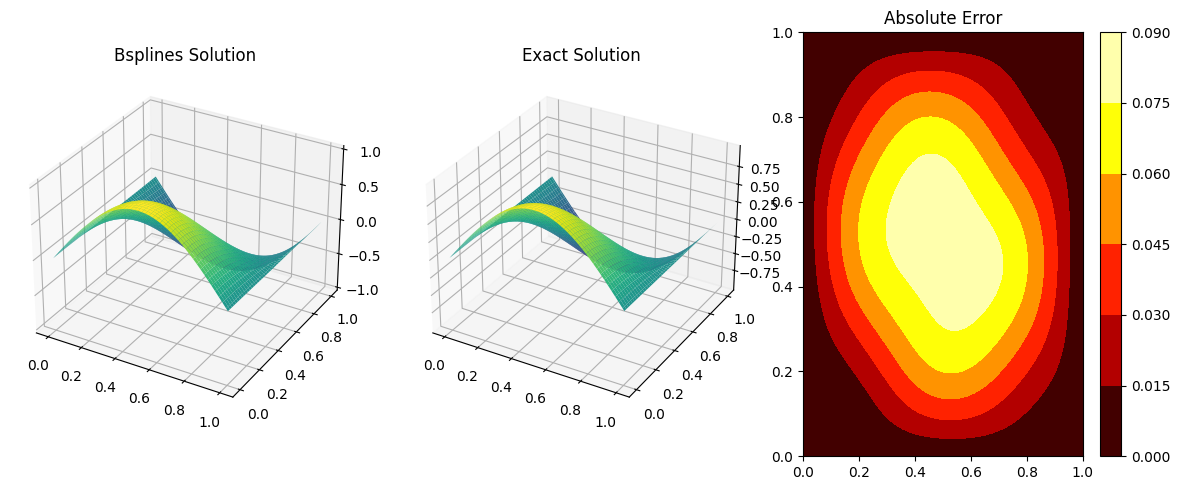

In [29]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
model.cpu()
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Tg)

# 📈 Plot predicted vs exact
fig = plt.figure(figsize=(12, 5))

# PINN solution
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(Xg, Tg, u_pred, cmap='viridis')
ax1.set_title("Bsplines Solution")

# Exact solution
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(Xg, Tg, u_exact, cmap='viridis')
ax2.set_title("Exact Solution")

# Absolute error
ax3 = fig.add_subplot(133)
error = np.abs(u_pred - u_exact)
c = ax3.contourf(Xg, Tg, error, cmap='hot')
fig.colorbar(c, ax=ax3)
ax3.set_title("Absolute Error")

plt.tight_layout()
plt.show()

Postprocessing

In [69]:
model.cpu()

PINN(
  (layers): ModuleList(
    (0): Linear(in_features=2, out_features=96, bias=True)
    (1-2): 2 x Linear(in_features=96, out_features=96, bias=True)
    (3): Linear(in_features=96, out_features=1, bias=True)
  )
  (activation): Tanh()
)

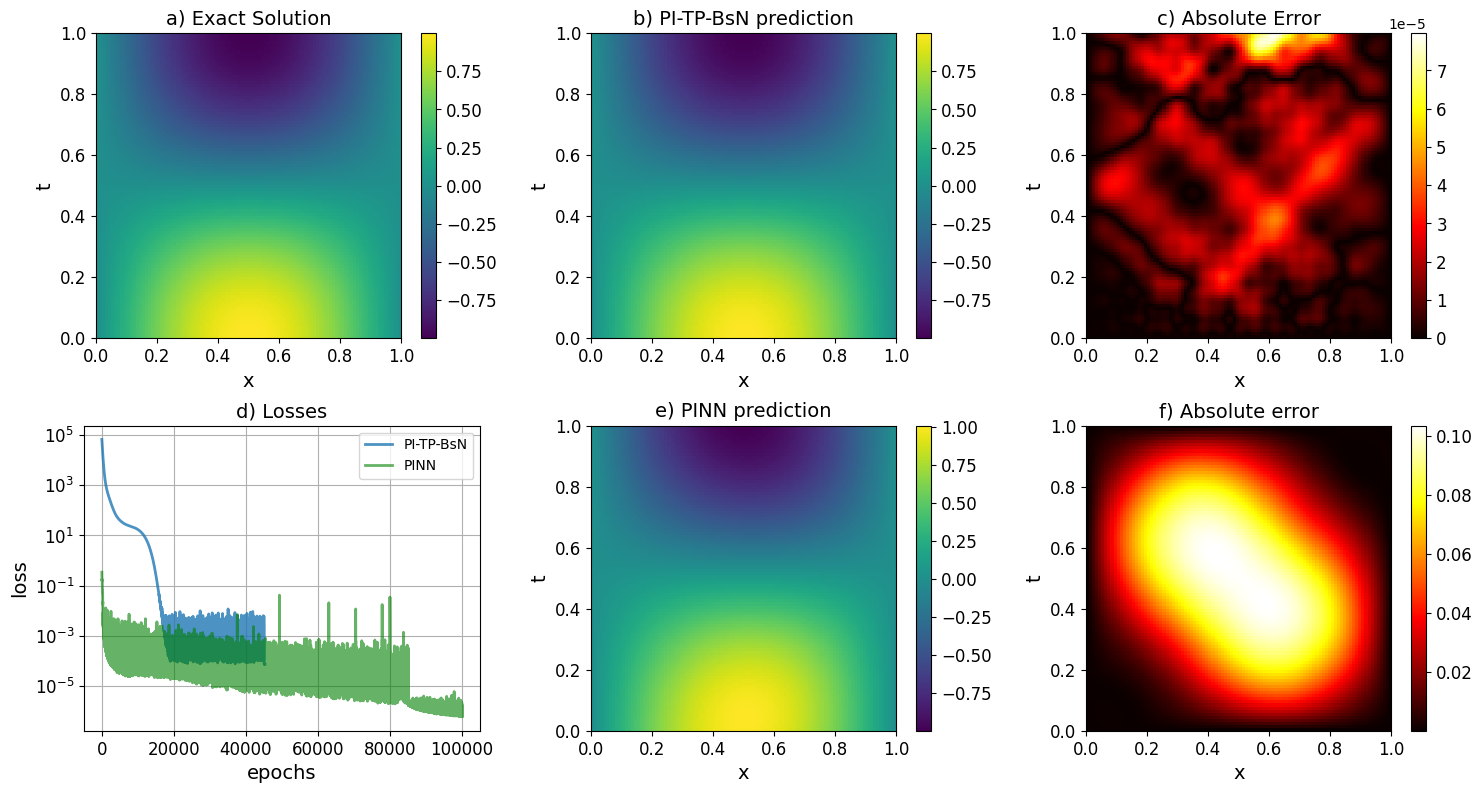

In [12]:
# Figure 12
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

with torch.no_grad():
    u_predp = model_ps.forward(XY_torch).numpy().reshape(Xg.shape)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Yg)

# Exact solution
im0 = axs[0,0].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,0].set_title("a) Exact Solution",fontsize=14)
axs[0,0].set_xlabel("x",fontsize=14)
axs[0,0].set_ylabel("t",fontsize=14)
axs[0,0].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im0, ax=axs[0,0])
cbar.ax.tick_params(labelsize=12) 

# B-splines solution
im1 = axs[0, 1].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,1].set_title("b) PI-TP-BsN prediction",fontsize=14)
axs[0,1].set_xlabel("x",fontsize=14)
axs[0,1].set_ylabel("t",fontsize=14)
axs[0,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im1, ax=axs[0, 1])
cbar.ax.tick_params(labelsize=12) 

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[0, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[0,2].set_title("c) Absolute Error",fontsize=14)
axs[0,2].set_xlabel("x",fontsize=14)
axs[0,2].set_ylabel("t",fontsize=14)
axs[0,2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im2, ax=axs[0, 2])
cbar.ax.tick_params(labelsize=12) 

# Losses
x_a = np.arange(len(loss_bsplines_s))
x_b = np.arange(len(loss_pinn))
axs[1, 0].plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
axs[1, 0].plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
axs[1, 0].legend()
axs[1, 0].set_yscale('log')
axs[1,0].set_title("d) Losses",fontsize=14)
axs[1,0].set_xlabel("epochs",fontsize=14)
axs[1,0].set_ylabel("loss",fontsize=14)
axs[1,0].tick_params(axis='both', labelsize=12)
axs[1,0].grid(True)
# cbar = fig.colorbar(im3, ax=axs[1, 0])
# cbar.ax.tick_params(labelsize=12) 

# Absolute error
im4 = axs[1, 1].imshow(u_predp, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1,1].set_title("e) PINN prediction",fontsize=14)
axs[1,1].set_xlabel("x",fontsize=14)
axs[1,1].set_ylabel("t",fontsize=14)
axs[1,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im4, ax=axs[1, 1])
cbar.ax.tick_params(labelsize=12) 

# Exact solution
error = np.abs(u_predp - u_exact)
im5 = axs[1, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[1, 2].set_title("f) Absolute error",fontsize=14)
axs[1, 2].set_xlabel("x",fontsize=14)
axs[1, 2].set_ylabel("t",fontsize=14)
axs[1, 2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im5, ax=axs[1, 2])
cbar.ax.tick_params(labelsize=12) 


# for ax in axs:
#     ax.set_xlabel("x",fontsize=14)
#     ax.set_ylabel("y",fontsize=14)
#     ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()

# fig.savefig("wave.pdf", dpi=300)
plt.show()

In [11]:
loss_pinn[-1]

6.089005637477385e-07

In [13]:
re = np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re

3.348414699694175e-05

In [14]:
rep = np.sqrt(np.sum((u_predp - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
rep

0.10964622797315535

In [15]:
(rep-re)/rep

0.9996946165169938

In [16]:
error = np.abs(u_pred - u_exact)
error.max()

7.971689733932141e-05

In [17]:
errorp = np.abs(u_predp - u_exact)
errorp.max()

0.10343243090366619

In [18]:
import math

a = 0.01
b = 0.003
delta_order = abs(math.log10(errorp.max()) - math.log10(error.max()))
print(f"Difference in orders of magnitude: {delta_order}")

Difference in orders of magnitude: 3.11310634455291
